# Loading the Datasets

## 1.1 Load both datasets from scikit-learn

In [1]:
import pandas as pd #tablolar için
import numpy as np #sayısal işlemler için
import matplotlib.pyplot as plt #grafik çizimleri için
import seaborn as sns #ısı haitası için 
from sklearn.datasets import load_breast_cancer; #veri setini yüklemek içi kullandım
from sklearn.model_selection import train_test_split #veri setini eğitim ve test olarak ayırmak için kullandım
#import hücresi
SEEDS=[42,52,62] #rastgele hasta grupları oluşturmak için kullandım
from sklearn.preprocessing import StandardScaler
#7.bölüm için modelin bulunduğu kütüphaneleri import ettim
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score  #modellerin başarı ölçüleri
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

In [2]:
load_data=load_breast_cancer()
#fonksiyonu kullanırken çağırırken load_data değişkenine atadık.

In [3]:
load_data.target_names

# 0 = malignant (kötü huylu)
# 1 = benign (iyi huylu)

array(['malignant', 'benign'], dtype='<U9')

In [4]:
load_data.feature_names
#sütun isimlerini yani hastanın özelliklerini gösterir

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [5]:
load_data.data
# ölçümleri verir 

array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]], shape=(569, 30))

## 1.2 Create the data frames

In [6]:
X = pd.DataFrame(load_data.data , columns= load_data.feature_names)
#burada ölçümlerimizi ve sütun isimlerimizi yani hastanın özelliklerini dataframe ile tablo haline getirdik.
Y = load_data.target
#hastanın kanser olup olmadığını belirten 0 ve 1 leri oluşturduk
X.head()
# x tablosunun ilk 5 satırını göster 

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [7]:
X.shape
#Satır ve süun sayısı bilgisini öğrendik.

(569, 30)

In [8]:
pd.Series(Y).value_counts() 
#0 ve 1 olarak yani ,y, huylu ve kötü huylu olarak kaç hastaya sahibiz

1    357
0    212
Name: count, dtype: int64

Bu bölümde kaç hastamız var hastalığının özellikleri gibi verileri oluşturduk

# 2. Dataset Quality Checks

## 2.1 Missing values and duplicates

In [9]:
X.isnull().sum()
#her hücreyi içi boş mu kontrol eder ve o sütundaki boş hücre sayısını gösterir

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

In [10]:
X.duplicated().sum()
#bu satırınaynısı var mı kontol eder ve kaç tane aynı satır oldugunu verir

np.int64(0)

eksik değer ve takrar eden değer yok bu yüzden doldurma ve silme işlemi yapmamıza gerek yok

## 2.2 Potential outliers

In [11]:
Q1 = X.quantile(0.25) # burada sütun değerlerinin yüzde 25 nin altında kaldığ sayıyı buluyoruz
Q3 =X.quantile(0.75) # burada sütun değerlerinin yüzde 75 nin altında kaldığ sayıyı buluyoruz
IQR = X.quantile(0.75) - X.quantile(0.25) #yüzde 50 lik kısımın genişliğini hesaplıyoruz
IQR

mean radius                  4.080000
mean texture                 5.630000
mean perimeter              28.930000
mean area                  362.400000
mean smoothness              0.018930
mean compactness             0.065480
mean concavity               0.101140
mean concave points          0.053690
mean symmetry                0.033800
mean fractal dimension       0.008420
radius error                 0.246500
texture error                0.640100
perimeter error              1.751000
area error                  27.340000
smoothness error             0.002977
compactness error            0.019370
concavity error              0.026960
concave points error         0.007072
symmetry error               0.008320
fractal dimension error      0.002310
worst radius                 5.780000
worst texture                8.640000
worst perimeter             41.290000
worst area                 568.700000
worst smoothness             0.029400
worst compactness            0.191900
worst concav

In [12]:
alt = Q1 - 1.5 * IQR #alt sınırı hesaplıyoruz
ust = Q3 + 1.5 * IQR #üst sınırı hesaplıyoruz
aykiri_sayisi=((X<alt) | X>ust).sum() #alt sınırda mı üst sınır da mı true false sayısını verir 
aykiri_sayisi.sort_values(ascending=False) #en çok aykırı değere sahip olan sütunları sıralar
#False ise büyükten küçüğe sıralar

mean smoothness            569
mean compactness           569
mean symmetry              569
radius error               569
mean fractal dimension     569
smoothness error           569
worst compactness          569
worst smoothness           569
worst symmetry             569
worst fractal dimension    569
symmetry error             569
fractal dimension error    569
compactness error          569
mean concave points        556
worst concave points       556
worst concavity            556
concavity error            556
concave points error       556
mean concavity             556
mean texture                 0
mean area                    0
mean radius                  0
area error                   0
perimeter error              0
texture error                0
mean perimeter               0
worst texture                0
worst radius                 0
worst perimeter              0
worst area                   0
dtype: int64

### Aykırı Değerlerin Algoritmalara Etkisi

Aykırı değerleri belirlemek için IQR (Interquartile Range) yöntemi kullanılmıştır. Q1 verilerin birinci çeyreğini, Q3 üçüncü çeyreğini temsil eder. IQR, Q3 ile Q1 arasındaki farktır. Q1 − 1.5 × IQR değerinin altında veya Q3 + 1.5 × IQR değerinin üstünde kalan gözlemler potansiyel aykırı değer olarak değerlendirilmiştir.

Aykırı değerler bazı makine öğrenmesi algoritmalarının performansını etkileyebilir:

- **K-Means:** Küme merkezlerini aritmetik ortalamayla hesapladığı için aykırı değerler küme merkezlerini kaydırabilir.
- **KNN:** Sınıflandırma yaparken örnekler arasındaki uzaklıkları kullandığından aykırı değerlerden etkilenebilir.
- **Gaussian Naive Bayes:** Her sınıftaki özelliklerin ortalamasını ve varyansını kullanarak olasılık hesapladığı için aykırı değerler bu hesaplamaları etkileyebilir.
- **Decision Tree:** Verileri belirli eşik değerlerine göre böldüğü için genellikle aykırı değerlere karşı daha dayanıklıdır. Ancak bazı durumlarda aykırı değerlerden etkilenebilir.

Bu çalışmada potansiyel aykırı değerler otomatik olarak silinmemiştir. Çünkü bu değerler hatalı ölçümler yerine gerçek gözlemleri temsil ediyor olabilir.

## 2.3 Data Types 

In [13]:
X.dtypes # her sütun ne tür sayı tutuyor 

mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

In [14]:
X.select_dtypes(include='number').shape[1]#sadee sayı gösteren sütunların sayısını söyler 

30

In [15]:
X.select_dtypes(include='object').shape[1]#sadee yazı gösteren sütunların sayısını söyler 

0

30 sütun hepi float64 geldi kategorik bir sütun çıkmadı

# 3. Exploratory Data Analysis (EDA)

## 3.1 Descriptive statistics

In [16]:
X.describe() #her sütun için tanımlayıcı bazı istatistikleri tablo şeklinde verir.

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


## 3.2 Class disttribution and correlation 

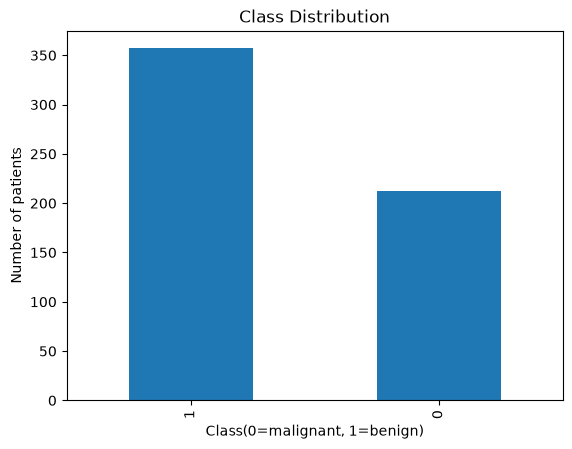

In [17]:
pd.Series(Y).value_counts().plot(kind='bar') # her sınıfta kaç hasta olduğunu hesaplıyor ve çubuk grafiğine çeviriyoruz
plt.title("Class Distribution") #grafiğe başlık ekliyoruz
plt.xlabel("Class(0=malignant, 1=benign)") #x eksenine başlık ekliyoruz
plt.ylabel("Number of patients") #y eksenine başlık ekliyoruz
plt.savefig("figures/bc_class_distribution.png") #grafiği kaydettik
plt.show()

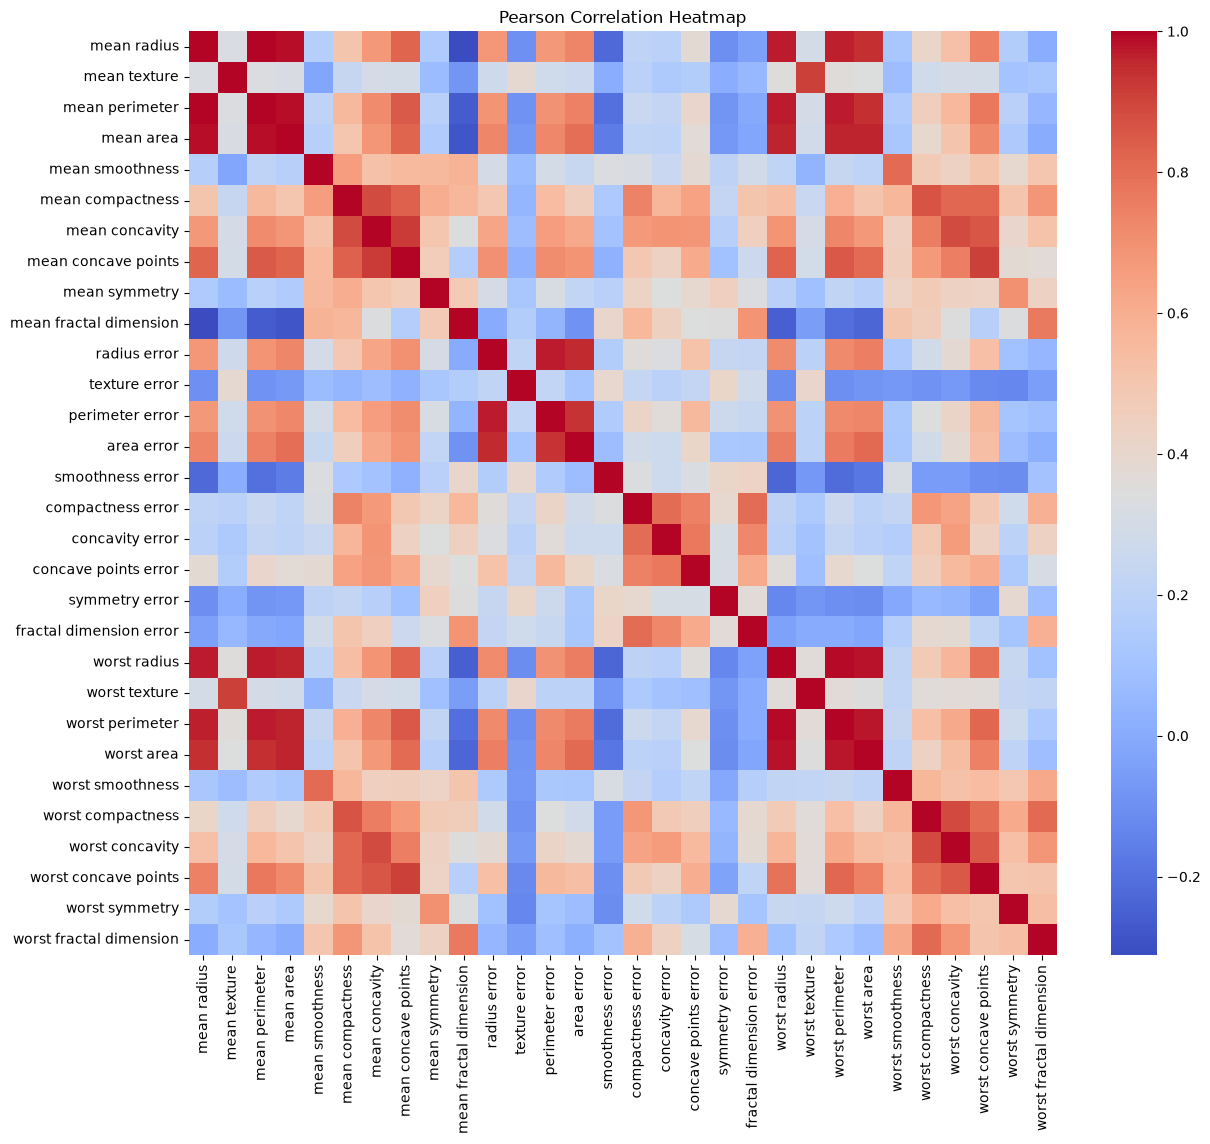

In [18]:
corra=X.corr() #sütunlar arasındaki korelasyonları hesaplıyoruz
plt.figure(figsize=(14,12)) #grafiğin boyutunu ayarladık
sns.heatmap(corra,cmap="coolwarm") #seaborn ile ısı haritasını çizdik renklendirmeyi cmap ile yaptık
plt.title("Pearson Correlation Heatmap") #grafiğe başlık ekledik
plt.savefig("figures/bc_correlation_heatmap.png") #grafiği kaydettik
plt.show() 

In [19]:
corra_abs=corra.abs() #korelasyon değerleriinin mutlak değerini aldık
ust =np.triu(np.ones(corra.shape),k=1).astype(bool)
ciftler= corra_abs.where(ust).stack()
sonuc =ciftler.sort_values(ascending=False).head(3)
sonuc

mean radius   mean perimeter     0.997855
worst radius  worst perimeter    0.993708
mean radius   mean area          0.987357
dtype: float64

### Korelasyon Analizi

Breast Cancer veri setindeki özellikler arasındaki ilişkileri incelemek için Pearson korelasyon yöntemi kullanılmıştır.

En yüksek korelasyona sahip üç özellik çifti şunlardır:

1. **mean radius – mean perimeter (0.9979):** Hücrenin ortalama yarıçapı ile ortalama çevresi arasında çok güçlü pozitif ilişki bulunmaktadır. Yarıçap arttıkça çevre de genellikle artmaktadır.

2. **worst radius – worst perimeter (0.9937):** En yüksek yarıçap ve çevre ölçümleri arasında çok güçlü pozitif ilişki bulunmaktadır. Bu özellikler hücre boyutuyla ilgili benzer bilgiler taşımaktadır.

3. **mean radius – mean area (0.9874):** Ortalama yarıçap ile ortalama alan arasında güçlü pozitif ilişki vardır. Yarıçap büyüdükçe hücrenin alanı da genellikle büyümektedir.

Bu sonuçlar, bazı özelliklerin birbirleriyle oldukça ilişkili olduğunu göstermektedir. Özellikle yarıçap, çevre ve alan ölçümleri benzer geometrik özellikleri temsil etmektedir. Ancak yüksek korelasyon, tek başına neden-sonuç ilişkisi olduğunu göstermez.

## 3.3 Boxplots

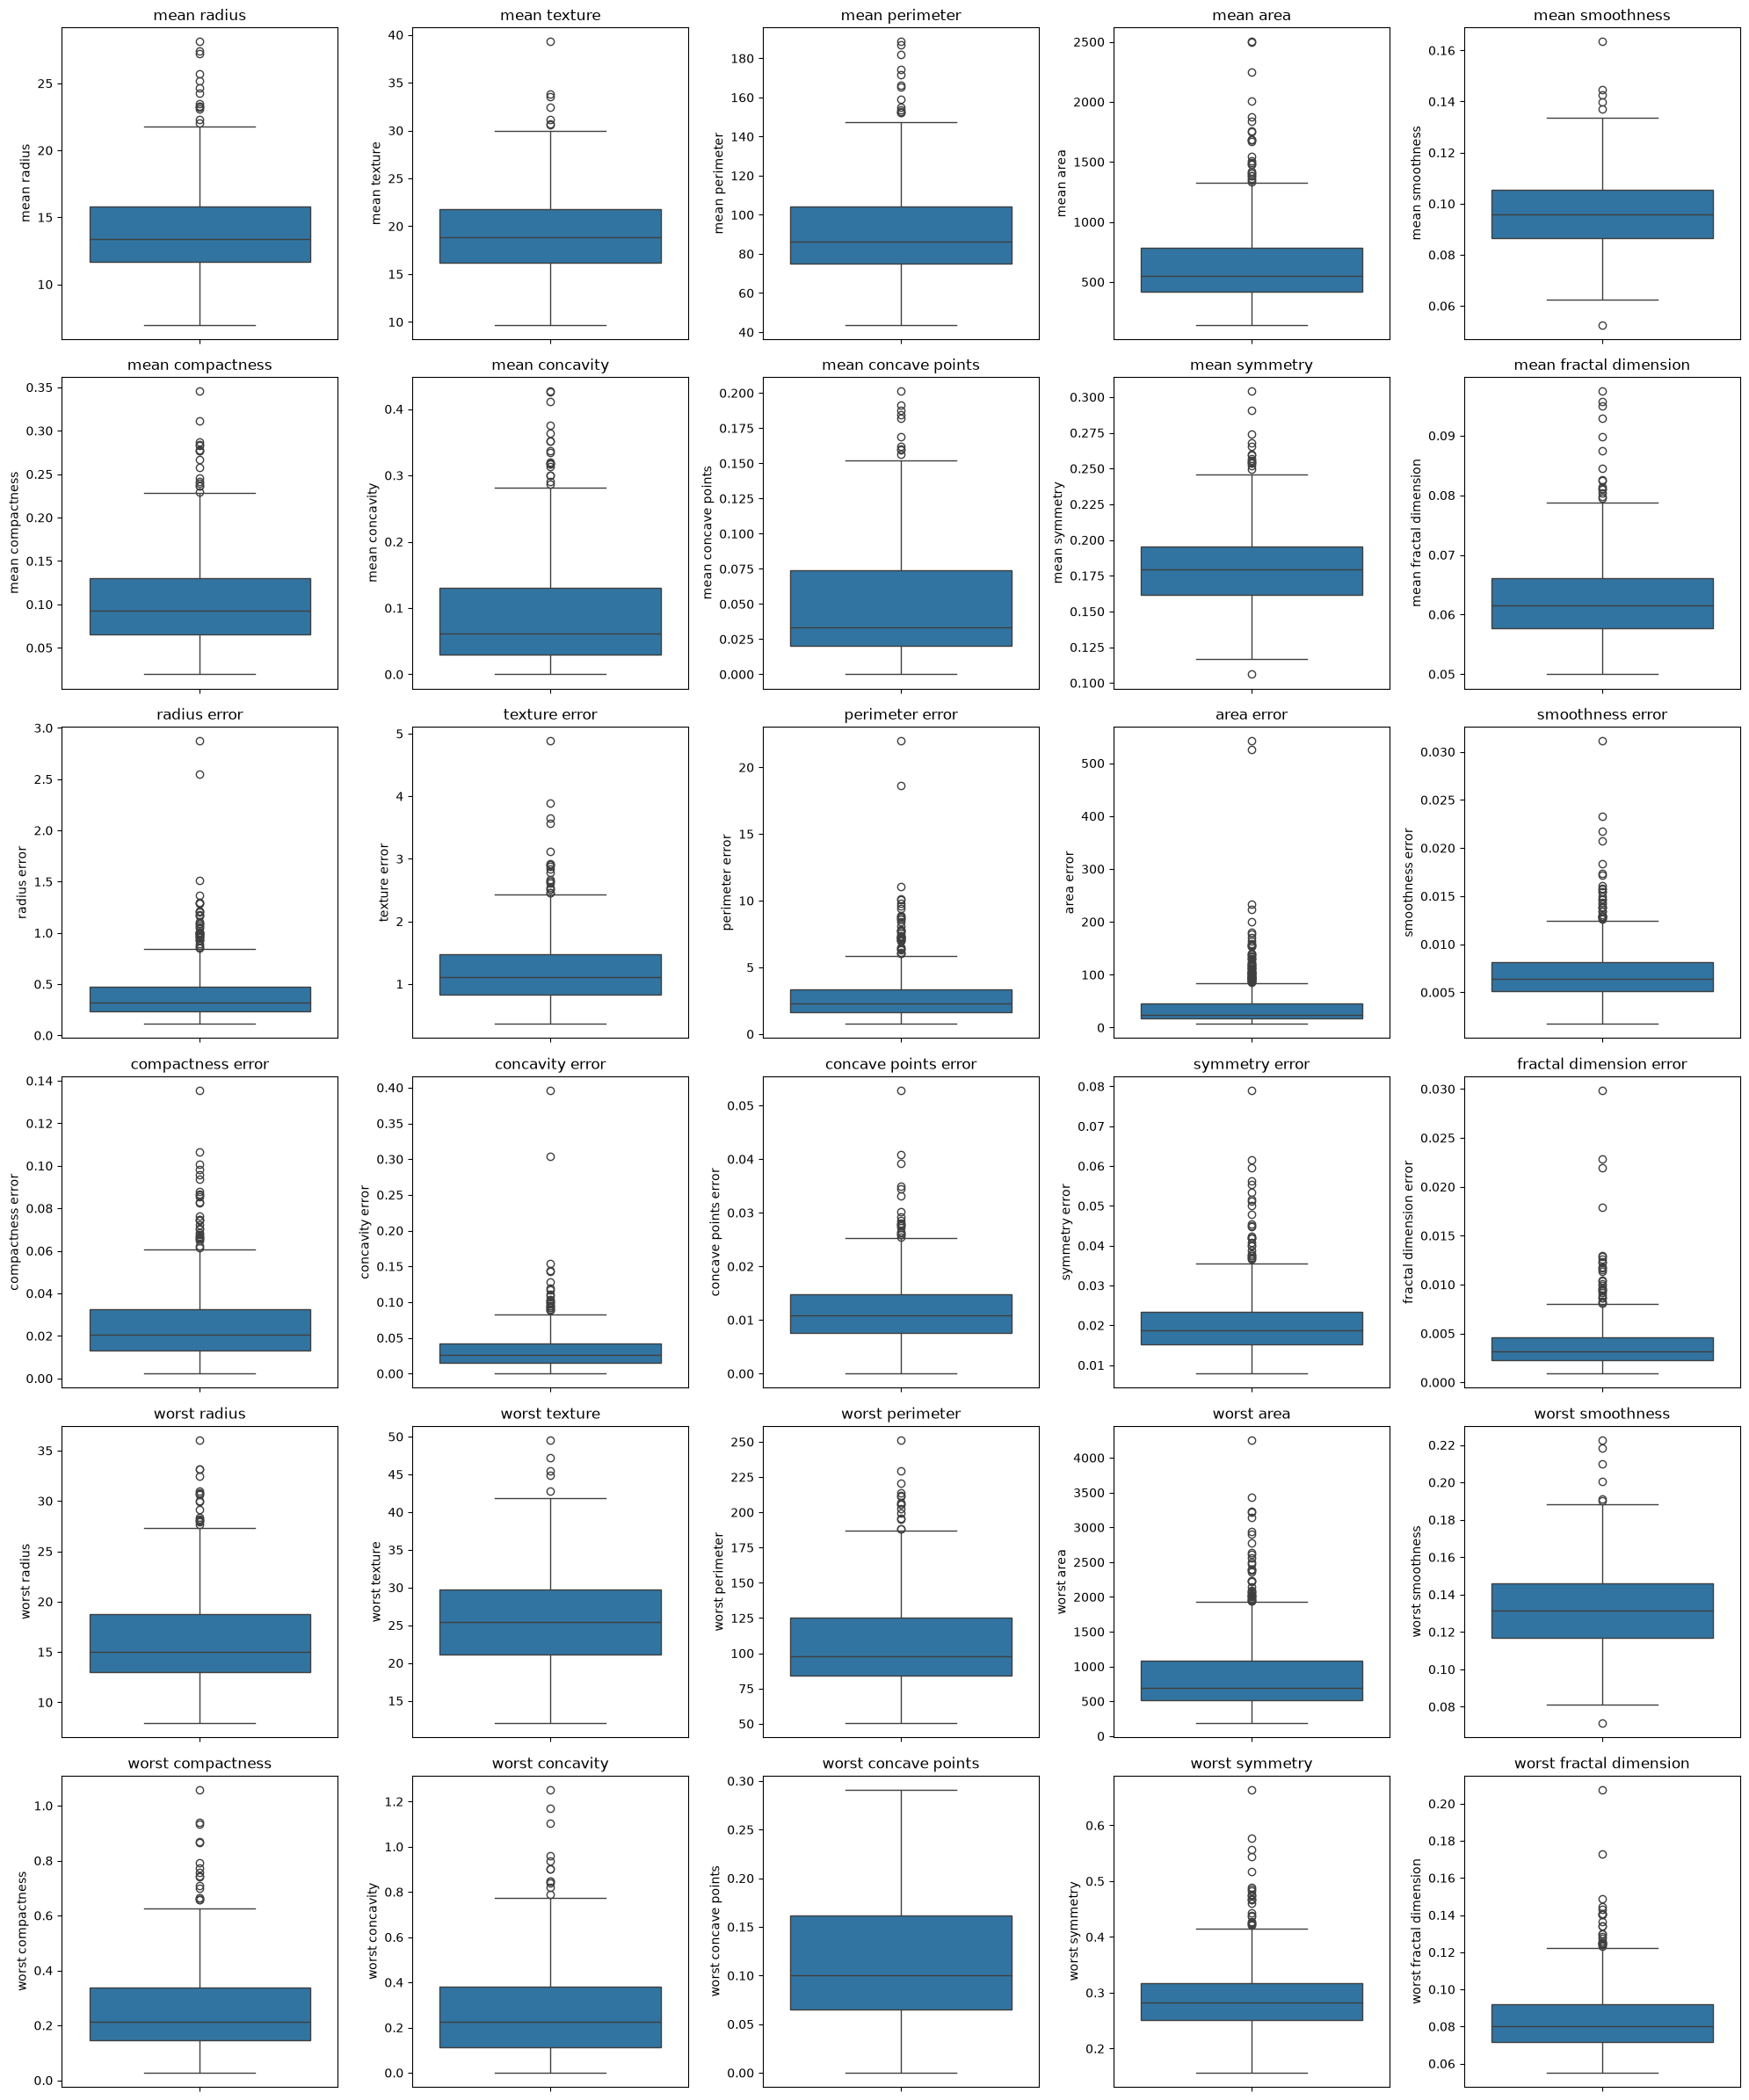

In [20]:
fig,axes=plt.subplots(6,5,figsize=(20,24)) #6 satır 5 sütunluk bir grafik oluşturduk
axes=axes.flatten() #düz liste oluşturduk
for i, column in enumerate(X.columns): #bütün sütunlara bakıyor
    sns.boxplot(y=X[column],ax=axes[i]) #her sütun için çizim yapıyoruz
    axes[i].set_title(column) #grafiğe başlık ekliyoruz
plt.tight_layout()#grafikler üst üste gelmesin
plt.savefig("figures/bc_boxplots.png") 
plt.show()

### Boxplot Analizi

Breast Cancer veri setindeki 30 özelliğin dağılımları boxplot grafikleriyle incelenmiştir.

Grafiklerde bazı özelliklerin değer aralıklarının diğerlerine göre daha geniş olduğu görülmektedir. Özellikle alan ve çevre gibi ölçümler, daha küçük ölçekli özelliklerden farklı değer aralıklarına sahiptir.

Bazı özelliklerde kutunun dışındaki noktalar potansiyel aykırı değerleri göstermektedir. Bu değerler özellikle uzaklık hesaplayan KNN ve küme merkezlerini kullanan K-Means algoritmalarını etkileyebilir.

Özelliklerin farklı ölçeklerde olması nedeniyle çalışmanın ilerleyen bölümlerinde StandardScaler uygulanarak ölçeklendirilmiş ve ölçeklendirilmemiş veriler karşılaştırılacaktır.

# 4. Splitting the Datasets

# 4.1 Fix the test set and repeat the training/validation split

In [21]:
X_trval, X_test, y_trval, y_test = train_test_split(X, Y, test_size=0.20, stratify=Y, random_state=42) 
#hastaların %20 sini test için ayırdık ve kalan %80 ini eğitim ve validation için ayırdık. stratify=y ile sınıfların eşit dağılmasını sağladık. random_state=42 ile rastgele seçim yaptık.
X_test.shape

(114, 30)

In [22]:
#kalan 455 hastayı 3 farklı seed’le (42, 52, 62) üç kere train ve validation’a bölüyor ve her bölmeyi seed numarasıyla bir sözlükte saklıyor.
splits = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.125, stratify=y_trval, random_state=seed)
    splits[seed] = {"X_train": X_train, "X_val": X_val, "y_train": y_train, "y_val": y_val} 
splits[42]["X_train"].shape

(398, 30)

## 4.2 Verify the split

In [23]:
#her seed için train, validation ve test parçalarında kaç hasta olduğunu, bunun tüm verinin yüzde kaçı ettiğini ve her parçada kaç malignant, kaç benign hasta olduğunu tek bir tabloda topladık.
rows = []
for seed in SEEDS:
    parcalar = {"train": (splits[seed]["X_train"], splits[seed]["y_train"]),
                "val": (splits[seed]["X_val"], splits[seed]["y_val"]),
                "test": (X_test, y_test)}
    for isim, (Xp, yp) in parcalar.items():
        rows.append({"seed": seed, "subset": isim, "count": len(Xp),
                     "percent": round(len(Xp) / len(X) * 100, 1),
                     "malignant (0)": (yp == 0).sum(), "benign (1)": (yp == 1).sum()})
split_summary = pd.DataFrame(rows)
split_summary
# Orijinal veri setindeki satır indeksleri
original_indices = set(X.index)

# Bir kez ayrılan sabit test setinin indeksleri
fixed_test_indices = set(X_test.index)

for seed in SEEDS:
    train_indices = set(splits[seed]["X_train"].index)
    val_indices = set(splits[seed]["X_val"].index)

    # Hiçbir satır iki farklı alt kümede bulunmamalı
    assert train_indices.isdisjoint(val_indices)
    assert train_indices.isdisjoint(fixed_test_indices)
    assert val_indices.isdisjoint(fixed_test_indices)

    # Bütün orijinal satırlar alt kümelerde bulunmalı
    assert (
        train_indices | val_indices | fixed_test_indices
        == original_indices
    )

    print(f"Seed {seed}: indeks kontrolleri başarılı")

print("Sabit test setindeki örnek sayısı:", len(fixed_test_indices))

Seed 42: indeks kontrolleri başarılı
Seed 52: indeks kontrolleri başarılı
Seed 62: indeks kontrolleri başarılı
Sabit test setindeki örnek sayısı: 114


In [24]:
# her seed için çakışma ve toplam kontrolü
for seed in SEEDS:
    tr = splits[seed]["X_train"]
    va = splits[seed]["X_val"]
    print("seed", seed)
    print("  train-val ortak:", len(set(tr.index) & set(va.index)))
    print("  train-test ortak:", len(set(tr.index) & set(X_test.index)))
    print("  val-test ortak:", len(set(va.index) & set(X_test.index)))
    print("  toplam 569 mu:", len(tr) + len(va) + len(X_test) == len(X))

seed 42
  train-val ortak: 0
  train-test ortak: 0
  val-test ortak: 0
  toplam 569 mu: True
seed 52
  train-val ortak: 0
  train-test ortak: 0
  val-test ortak: 0
  toplam 569 mu: True
seed 62
  train-val ortak: 0
  train-test ortak: 0
  val-test ortak: 0
  toplam 569 mu: True


test bir kere seed 42 ile ayrıldı ve hiç değişmiyor
kalan kısım 3 seed ile %70 train / %10 validation olarak bölündü
çakışma yok, toplamlar tutuyor, sınıf oranları korunmuş

# 5. Data Preprocessing and Scaling

## 5.1 Handle missing values, if present
2.1'de eksik değer olmadığını gördük, bu yüzden imputation adımı eklemedik.

## 5.2 Select one scaler
StandardScaler seçtik. Her sütunu ortalaması 0, standart sapması 1 olacak şekilde dönüştürüyor. Böylece büyük sayılı sütunlar (ör. area) uzaklık hesabında diğerlerini ezmiyor.

## 5.3 Fit and apply the scaler correctly

In [25]:
scalers = {}
for seed in SEEDS:
    scaler = StandardScaler() # her seed için yeni scaler
    scaler.fit(splits[seed]["X_train"]) # sadece train'den öğren
    splits[seed]["X_train_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_train"]),
        columns=X.columns, index=splits[seed]["X_train"].index)
    splits[seed]["X_val_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_val"]),
        columns=X.columns, index=splits[seed]["X_val"].index)
    scalers[seed] = scaler   # scaler'ı sakla

# test sadece seed 42'nin scaler'ı ile dönüştürülür
X_test_scaled = pd.DataFrame(scalers[42].transform(X_test),
                             columns=X.columns, index=X_test.index)

In [26]:
splits[42]["X_train"].head()   # seed 42, ölçeklemeden önce

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075


In [27]:
splits[42]["X_train_scaled"].head()   # seed 42, ölçeklemeden sonra

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
446,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420


Ölçeklendirme öncesinde özellikler farklı sayısal aralıklara sahipti. Örneğin `mean area` gibi özellikler yüzler seviyesinde değerler alırken `mean smoothness` gibi özellikler çok daha küçük değerlere sahipti.

StandardScaler, her özelliği eğitim verisinden hesaplanan ortalama ve standart sapmaya göre dönüştürür. Böylece eğitim verisindeki özelliklerin ortalaması yaklaşık 0, standart sapması yaklaşık 1 olur. Ancak bütün değerlerin -3 ile +3 arasında olması garanti değildir.

Veri sızıntısını önlemek için her seed'de StandardScaler yalnızca eğitim verisine fit edilmiştir. Validation verisi ilgili seed'in scaler'ı ile, sabit test verisi ise seed 42'nin scaler'ı ile dönüştürülmüştür.

# 6. Preparing the Two Data Representations
Her seed için iki versiyon var: ölçeksiz (X_train, X_val) ve ölçekli (X_train_scaled, X_val_scaled). İkisi de aynı hastaları içeriyor; modelleri ikisinde de eğitip ölçeklemenin etkisini karşılaştıracağız.

# 7. Training the Classification Models
## 7.1 Required experiments

In [28]:
import sklearn
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
#kullandığımız paketlerin sürümleri

pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1


In [29]:
# denenecek 11 ayar: 5 ağaç derinliği, 5 komşu sayısı, 1 Naive Bayes
ayarlar = []
for d in [2, 3, 5, 10, None]:
    ayarlar.append(("dt", d))
for k in [1, 3, 5, 7, 11]:
    ayarlar.append(("knn", k))
ayarlar.append(("gnb", None))

# algoritma adına ve ayara göre model oluşturur
def model_olustur(algo, param, seed):
    if algo == "dt":
        return DecisionTreeClassifier(max_depth=param, random_state=seed)
    if algo == "knn":
        return KNeighborsClassifier(n_neighbors=param, weights="uniform", metric="euclidean")
    return GaussianNB()

# ayarı kısa bir etikete çevirir: d3, k5, default
def param_etiketi(algo, param):
    if algo == "dt":
        return f"d{param}"
    if algo == "knn":
        return f"k{param}"
    return "default"

In [30]:
# bir modelin validation verisindeki 5 metriğini hesaplar
def hesapla_metrikler(model, Xv, yv):
    tahmin = model.predict(Xv)
    olasilik = model.predict_proba(Xv)

    # Precision ve recall için tanımsız durumları kontrol et
    undefined_precision = []
    undefined_recall = []

    for sinif in model.classes_:
        predicted_count = np.sum(tahmin == sinif)
        actual_count = np.sum(np.asarray(yv) == sinif)

        if predicted_count == 0:
            undefined_precision.append(int(sinif))

        if actual_count == 0:
            undefined_recall.append(int(sinif))

    # Validation metrikleri
    sonuc = {
        "val_accuracy": accuracy_score(yv, tahmin),
        "val_precision": precision_score(
            yv, tahmin, average="macro", zero_division=0
        ),
        "val_recall": recall_score(
            yv, tahmin, average="macro", zero_division=0
        ),
        "val_f1": f1_score(
            yv, tahmin, average="macro", zero_division=0
        ),
        "undefined_precision_classes": str(undefined_precision),
        "undefined_recall_classes": str(undefined_recall),
    }

    # ROC-AUC
    if len(model.classes_) == 2:
        poz = list(model.classes_).index(0)

        sonuc["val_roc_auc"] = roc_auc_score(
            (np.asarray(yv) == 0).astype(int),
            olasilik[:, poz]
        )
    else:
        sonuc["val_roc_auc"] = roc_auc_score(
            yv,
            olasilik,
            multi_class="ovr",
            average="macro",
            labels=model.classes_
        )

    return sonuc

## 7.2 Record and compare the experiments

In [31]:
DATASET = "bc"
runs = []          # her eğitimin sonucu buraya
models_s42 = {}    # seed 42 modellerini test için saklıyoruz

for seed in SEEDS:
    for rep in ["unscaled", "scaled"]:
        if rep == "unscaled":
            Xtr, Xv = splits[seed]["X_train"], splits[seed]["X_val"]
        else:
            Xtr, Xv = splits[seed]["X_train_scaled"], splits[seed]["X_val_scaled"]
        ytr, yv = splits[seed]["y_train"], splits[seed]["y_val"]

        for algo, param in ayarlar:
            model = model_olustur(algo, param, seed)
            model.fit(Xtr, ytr)                     # sadece train ile eğit
            etiket = param_etiketi(algo, param)
            config_id = f"{DATASET}_{algo}_{rep}_{etiket}"
            tr_tahmin = model.predict(Xtr)
            satir = {"run_id": f"{config_id}_s{seed}", "config_id": config_id,
                     "dataset": DATASET, "seed": seed, "algorithm": algo,
                     "representation": rep, "param": etiket,
                     "train_accuracy": accuracy_score(ytr, tr_tahmin),
                     "train_f1": f1_score(ytr, tr_tahmin, average="macro")}
            satir.update(hesapla_metrikler(model, Xv, yv))
            runs.append(satir)
            if seed == 42:
                models_s42[config_id] = model

runs_df = pd.DataFrame(runs)
print("Toplam eğitim:", len(runs_df))
runs_df.head()

Toplam eğitim: 66


,run_id,config_id,dataset,seed,algorithm,representation,param,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,undefined_precision_classes,undefined_recall_classes,val_roc_auc
0,bc_dt_unscaled_d2_s42,bc_dt_unscaled_d2,bc,42,dt,unscaled,d2,0.954774,0.951595,0.894737,0.894737,0.876984,0.884459,[],[],0.875661
1,bc_dt_unscaled_d3_s42,bc_dt_unscaled_d3,bc,42,dt,unscaled,d3,0.972362,0.970031,0.894737,0.894737,0.876984,0.884459,[],[],0.919312
2,bc_dt_unscaled_d5_s42,bc_dt_unscaled_d5,bc,42,dt,unscaled,d5,0.997487,0.997314,0.912281,0.909459,0.900794,0.904778,[],[],0.921296
3,bc_dt_unscaled_d10_s42,bc_dt_unscaled_d10,bc,42,dt,unscaled,d10,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,[],[],0.924603
4,bc_dt_unscaled_dNone_s42,bc_dt_unscaled_dNone,bc,42,dt,unscaled,dNone,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,[],[],0.924603


Bu bölümde üç modeli eğittim: Decision Tree , KNN ve Naive Bayes. Her birini hem ölçeksiz hem ölçekli veride, üç farklı seed için çalıştırdım, toplamda 66 model oldu. Modelleri sadece train verisiyle eğittim. Her çalıştırmaya hangi model, hangi ayar ve hangi seed olduğu anlaşılsın diye bir isim verdim. Seed 42'deki modelleri de en sonda test için ayrıca sakladım.

# 8. Measuring Validation Performance
## 8.1 Required metrics
Metrikler hesapla_metrikler fonksiyonunda validation verisi üzerinde hesaplandı: accuracy, macro precision, macro recall, macro F1 ve ROC-AUC. ROC-AUC'de malignant (0) pozitif sınıf alındı ve olasılıklar kullanıldı.
## 8.2 Comparison tables and model selection

In [32]:
pd.set_option("display.max_rows", 100)   # satırların hepsini ekranda gösterdim
runs_df

,run_id,config_id,dataset,seed,algorithm,representation,param,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,undefined_precision_classes,undefined_recall_classes,val_roc_auc
0,bc_dt_unscaled_d2_s42,bc_dt_unscaled_d2,bc,42,dt,unscaled,d2,0.954774,0.951595,0.894737,0.894737,0.876984,0.884459,[],[],0.875661
1,bc_dt_unscaled_d3_s42,bc_dt_unscaled_d3,bc,42,dt,unscaled,d3,0.972362,0.970031,0.894737,0.894737,0.876984,0.884459,[],[],0.919312
2,bc_dt_unscaled_d5_s42,bc_dt_unscaled_d5,bc,42,dt,unscaled,d5,0.997487,0.997314,0.912281,0.909459,0.900794,0.904778,[],[],0.921296
3,bc_dt_unscaled_d10_s42,bc_dt_unscaled_d10,bc,42,dt,unscaled,d10,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,[],[],0.924603
4,bc_dt_unscaled_dNone_s42,bc_dt_unscaled_dNone,bc,42,dt,unscaled,dNone,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,[],[],0.924603
5,bc_knn_unscaled_k1_s42,bc_knn_unscaled_k1,bc,42,knn,unscaled,k1,1.000000,1.000000,0.859649,0.855263,0.839286,0.845946,[],[],0.839286
6,bc_knn_unscaled_k3_s42,bc_knn_unscaled_k3,bc,42,knn,unscaled,k3,0.959799,0.956730,0.877193,0.880342,0.853175,0.863590,[],[],0.916005
7,bc_knn_unscaled_k5_s42,bc_knn_unscaled_k5,bc,42,knn,unscaled,k5,0.952261,0.948690,0.894737,0.894737,0.876984,0.884459,[],[],0.929894
8,bc_knn_unscaled_k7_s42,bc_knn_unscaled_k7,bc,42,knn,unscaled,k7,0.949749,0.945912,0.912281,0.909459,0.900794,0.904778,[],[],0.951058
9,bc_knn_unscaled_k11_s42,bc_knn_unscaled_k11,bc,42,knn,unscaled,k11,0.947236,0.943125,0.929825,0.934211,0.914683,0.922973,[],[],0.955026


In [33]:
metrikler = ["train_accuracy", "train_f1", "val_accuracy", "val_precision",
             "val_recall", "val_f1", "val_roc_auc"]
# aynı ayarın 3 seed'deki sonuçlarını grupla, ortalama ve standart sapma al (std varsayılan olarak ddof=1)
summary = runs_df.groupby(["config_id", "algorithm", "representation", "param"])[metrikler].agg(["mean", "std"])
summary.columns = [f"{m}_{s}" for m, s in summary.columns]   # sütun adlarını düzleştir: val_f1_mean gibi
summary = summary.reset_index()
summary.insert(0, "dataset", DATASET)
print("Özet satır sayısı:", len(summary))
summary

Özet satır sayısı: 22


,dataset,config_id,algorithm,representation,param,train_accuracy_mean,train_accuracy_std,train_f1_mean,train_f1_std,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_f1_mean,val_f1_std,val_roc_auc_mean,val_roc_auc_std
0,bc,bc_dt_scaled_d10,dt,scaled,d10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
1,bc,bc_dt_scaled_d2,dt,scaled,d2,0.955611,0.003838,0.952682,0.004089,0.918129,0.020258,0.913139,0.016097,0.912037,0.030759,0.911679,0.023583,0.921958,0.040441
2,bc,bc_dt_scaled_d3,dt,scaled,d3,0.975712,0.003838,0.973926,0.004230,0.923977,0.026799,0.919867,0.023128,0.916667,0.036370,0.917684,0.030362,0.941358,0.020939
3,bc,bc_dt_scaled_d5,dt,scaled,d5,0.994975,0.004352,0.994614,0.004677,0.923977,0.020258,0.916735,0.018249,0.923280,0.030759,0.918785,0.022660,0.930115,0.025004
4,bc,bc_dt_scaled_dNone,dt,scaled,dNone,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
5,bc,bc_dt_unscaled_d10,dt,unscaled,d10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
6,bc,bc_dt_unscaled_d2,dt,unscaled,d2,0.955611,0.003838,0.952682,0.004089,0.918129,0.020258,0.913139,0.016097,0.912037,0.030759,0.911679,0.023583,0.921958,0.040441
7,bc,bc_dt_unscaled_d3,dt,unscaled,d3,0.975712,0.003838,0.973926,0.004230,0.923977,0.026799,0.919867,0.023128,0.916667,0.036370,0.917684,0.030362,0.941358,0.020939
8,bc,bc_dt_unscaled_d5,dt,unscaled,d5,0.994975,0.004352,0.994614,0.004677,0.923977,0.020258,0.916735,0.018249,0.923280,0.030759,0.918785,0.022660,0.930115,0.025004
9,bc,bc_dt_unscaled_dNone,dt,unscaled,dNone,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952


In [34]:
# ödevin kuralı: en yüksek ortalama val F1 → eşitlikte ortalama val accuracy → daha düşük F1 std → alfabetik config_id
secim = summary.sort_values(by=["val_f1_mean", "val_accuracy_mean", "val_f1_std", "config_id"],
                            ascending=[False, False, True, True])
best_config = secim.iloc[0]["config_id"]
print("Seçilen konfigürasyon:", best_config)
secim.head(5)

Seçilen konfigürasyon: bc_knn_scaled_k7


,dataset,config_id,algorithm,representation,param,train_accuracy_mean,train_accuracy_std,train_f1_mean,train_f1_std,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_f1_mean,val_f1_std,val_roc_auc_mean,val_roc_auc_std
16,bc,bc_knn_scaled_k7,knn,scaled,k7,0.972362,0.002513,0.970234,0.002752,0.970760,0.026799,0.978408,0.019661,0.960317,0.036370,0.967675,0.029718,0.978175,0.019384
13,bc,bc_knn_scaled_k11,knn,scaled,k11,0.971524,0.001451,0.969381,0.001509,0.964912,0.035088,0.974561,0.025012,0.952381,0.047619,0.960846,0.039478,0.994489,0.004785
14,bc,bc_knn_scaled_k3,knn,scaled,k3,0.980737,0.003838,0.979314,0.004134,0.959064,0.020258,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979277,0.016151
15,bc,bc_knn_scaled_k5,knn,scaled,k5,0.974037,0.002901,0.972117,0.003158,0.959064,0.020258,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979497,0.017386
12,bc,bc_knn_scaled_k1,knn,scaled,k1,1.000000,0.000000,1.000000,0.000000,0.941520,0.020258,0.940964,0.028337,0.933862,0.016038,0.936898,0.021295,0.933862,0.016038


In [35]:
# Deney sayıları ve sonuç tablolarının kontrolü

expected_runs = len(SEEDS) * 2 * len(ayarlar)
expected_configs = 2 * len(ayarlar)

print("Beklenen deney sayısı:", expected_runs)
print("Gerçek deney sayısı:", len(runs_df))

print("Beklenen konfigürasyon sayısı:", expected_configs)
print("Gerçek konfigürasyon sayısı:", len(summary))

print("Eksik metrik sayıları:")
print(
    runs_df[
        ["val_accuracy", "val_precision",
         "val_recall", "val_f1", "val_roc_auc"]
    ].isna().sum()
)

assert len(runs_df) == expected_runs
assert len(summary) == expected_configs
assert runs_df["run_id"].is_unique
assert runs_df.groupby("config_id")["seed"].nunique().eq(len(SEEDS)).all()

print("\nTüm deney kontrolleri başarılı.")

Beklenen deney sayısı: 66
Gerçek deney sayısı: 66
Beklenen konfigürasyon sayısı: 22
Gerçek konfigürasyon sayısı: 22
Eksik metrik sayıları:
val_accuracy     0
val_precision    0
val_recall       0
val_f1           0
val_roc_auc      0
dtype: int64

Tüm deney kontrolleri başarılı.


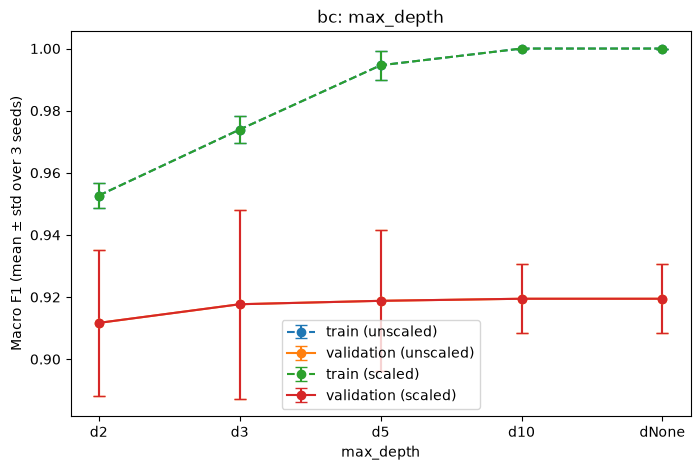

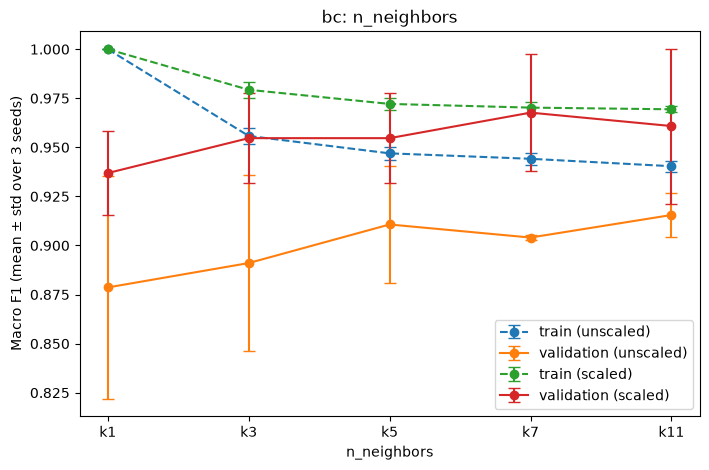

In [36]:
# bir algoritmanın parametresine göre ortalama train ve validation F1'ini çizer, hata çubukları = seed std
def parametre_grafigi(algo, etiketler, xlabel, dosya):
    plt.figure(figsize=(8, 5))
    for rep in ["unscaled", "scaled"]:
        alt = summary[(summary["algorithm"] == algo) & (summary["representation"] == rep)]
        alt = alt.set_index("param").loc[etiketler]
        plt.errorbar(etiketler, alt["train_f1_mean"], yerr=alt["train_f1_std"],
                     marker="o", linestyle="--", capsize=4, label=f"train ({rep})")
        plt.errorbar(etiketler, alt["val_f1_mean"], yerr=alt["val_f1_std"],
                     marker="o", capsize=4, label=f"validation ({rep})")
    plt.xlabel(xlabel)
    plt.ylabel("Macro F1 (mean ± std over 3 seeds)")
    plt.title(f"{DATASET}: {xlabel}")
    plt.legend()
    plt.savefig(dosya, bbox_inches="tight")
    plt.show()

parametre_grafigi("dt", ["d2", "d3", "d5", "d10", "dNone"], "max_depth", "figures/bc_tree_depth.png")
parametre_grafigi("knn", ["k1", "k3", "k5", "k7", "k11"], "n_neighbors", "figures/bc_knn_neighbors.png")

Seçilen model bc_knn_scaled_k7 oldu, ortalama validation F1 0.968 (std 0.030).

Scaling en çok KNN'i etkiledi. Mesela k=7'de unscaled F1 0.904 iken scaled 0.968 oldu, k=1'de de 0.879'dan 0.937'ye çıktı. KNN uzaklıkla çalıştığı için scale etmeyince area gibi büyük sütunlar her şeyi belirliyor. Decision Tree'de scaled ve unscaled sonuçlar tamamen aynı çıktı, o yüzden grafikte unscaled çizgiler scaled çizgilerin altında kalıp görünmüyor. Naive Bayes'te de fark çok az (0.937 vs 0.925).

Tree derinliği arttıkça train F1 1.0'a kadar çıkıyor ama validation F1 0.91-0.92 civarında kalıyor, yani derin ağaç ezberliyor (overfitting). d10 ve dNone aynı sonucu verdi, ağaç zaten 10 derinliğe gelmeden bitiyor. KNN'de k büyüdükçe her zaman iyileşmiyor, en iyisi k=7 oldu, k=11'de biraz düştü. k=1'de train F1 1.0 ama validation daha düşük, bu da ezberleme.

Std değerleri 0.01 ile 0.06 arasında, validation seti küçük olduğu için (57 hasta) seed'e göre sonuçlar biraz oynuyor. Bu std sadece 3 farklı bölmedeki değişimi gösteriyor, istatistiksel bir kanıt değil.

# 9. Evaluating the Selected Models on the Test Sets
## 9.1 Final performance metrics

In [37]:
# seçilen konfigürasyonun seed 42 modelini ve doğru veri versiyonunu al
best_row = secim.iloc[0]
final_model = models_s42[best_config]
if best_row["representation"] == "scaled":
    X_test_final = X_test_scaled
else:
    X_test_final = X_test

# 8. bölümdeki fonksiyonla test metriklerini hesapla, isimleri test_ yap
test_metrikleri = hesapla_metrikler(final_model, X_test_final, y_test)
test_metrikleri = {k.replace("val_", "test_"): v for k, v in test_metrikleri.items()}

classifier_test = pd.DataFrame([{
    "dataset": DATASET, "selected_config": best_config, "evaluation_seed": 42,
    "val_f1_mean": best_row["val_f1_mean"], "val_f1_std": best_row["val_f1_std"],
    "test_accuracy": test_metrikleri["test_accuracy"],
    "test_precision": test_metrikleri["test_precision"],
    "test_recall": test_metrikleri["test_recall"],
    "test_f1": test_metrikleri["test_f1"],
    "test_roc_auc": test_metrikleri["test_roc_auc"]}])
classifier_test

,dataset,selected_config,evaluation_seed,val_f1_mean,val_f1_std,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,bc,bc_knn_scaled_k7,42,0.967675,0.029718,0.973684,0.98,0.964286,0.971277,0.988757


In [38]:
# Test sonuçlarını kontrol et

print("Seçilen model:", best_config)
print("Test örnek sayısı:", len(X_test_final))
print("Test sonuç tablosu satır sayısı:", len(classifier_test))

print("\nTest metrikleri:")
print(classifier_test[[
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_roc_auc"
]].round(4))

assert len(X_test_final) == len(X_test)
assert len(classifier_test) == 1

for metrik in [
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_roc_auc"
]:
    deger = classifier_test.iloc[0][metrik]
    assert 0 <= deger <= 1, f"Geçersiz metrik: {metrik}"

print("\nTest kontrolleri başarılı.")

Seçilen model: bc_knn_scaled_k7
Test örnek sayısı: 114
Test sonuç tablosu satır sayısı: 1

Test metrikleri:
   test_accuracy  test_precision  test_recall  test_f1  test_roc_auc
0         0.9737            0.98       0.9643   0.9713        0.9888

Test kontrolleri başarılı.


In [39]:
test_tahmin = final_model.predict(X_test_final)
print(classification_report(y_test, test_tahmin, target_names=load_data.target_names, digits=4))

              precision    recall  f1-score   support

   malignant     1.0000    0.9286    0.9630        42
      benign     0.9600    1.0000    0.9796        72

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



Seçtiğim model bc_knn_scaled_k7, seed 42 modelini test setinde bir kere çalıştırdım. Test sonuçları: accuracy 0.974, macro precision 0.980, macro recall 0.964, macro F1 0.971, ROC-AUC 0.989. Validation'da ortalama F1 0.968'di (std 0.030), test F1 de 0.971 çıktı, yani ikisi birbirine çok yakın, model validation'daki kadar iyi çalışıyor. Test sonucuna bakıp modeli değiştirmedim.

## 9.2 Confusion matrices

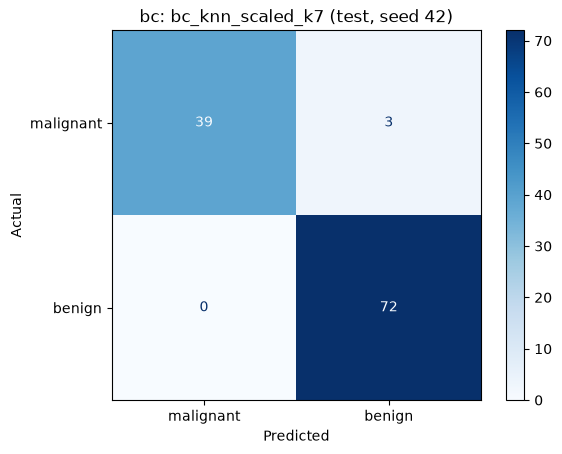

array([[39,  3],
       [ 0, 72]])

In [40]:
# sıra [0, 1] = [malignant, benign]; satırlar Actual, sütunlar Predicted
cm = confusion_matrix(y_test, test_tahmin, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot(cmap="Blues", values_format="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"{DATASET}: {best_config} (test, seed 42)")
plt.savefig("figures/bc_confusion_matrix.png", bbox_inches="tight")
plt.show()
cm

In [41]:
# bu sırada: [0,0]=TP, [0,1]=FN, [1,0]=FP, [1,1]=TN
TP, FN = cm[0, 0], cm[0, 1]
FP, TN = cm[1, 0], cm[1, 1]
precision_m = TP / (TP + FP)
recall_m = TP / (TP + FN)
f1_m = 2 * precision_m * recall_m / (precision_m + recall_m)
print("TP:", TP, "FN:", FN, "FP:", FP, "TN:", TN)
print("malignant precision:", round(precision_m, 4))
print("malignant recall:", round(recall_m, 4))
print("malignant F1:", round(f1_m, 4))

TP: 39 FN: 3 FP: 0 TN: 72
malignant precision: 1.0
malignant recall: 0.9286
malignant F1: 0.963


Malignant'ı pozitif sınıf aldım. Sıra [malignant, benign] olduğu için matristeki yerler normal alışılan düzenden farklı: sol üst TP, sağ üst FN, sol alt FP, sağ alt TN.
TP = 39: malignant olan 39 hastayı doğru bilmiş.
FN = 3: 3 malignant hastaya yanlışlıkla benign demiş.
FP = 0: benign olan hiçbir hastaya malignant dememiş.
TN = 72: 72 benign hastayı doğru bilmiş.

Elle hesap: precision = 39 / (39 + 0) = 1.0, recall = 39 / (39 + 3) = 0.9286, F1 = 2 × 1.0 × 0.9286 / (1.0 + 0.9286) = 0.963. Bunlar classification report'taki malignant satırıyla aynı (macro ortalama ile değil, malignant satırıyla karşılaştırdım).

## 9.3 ROC curves

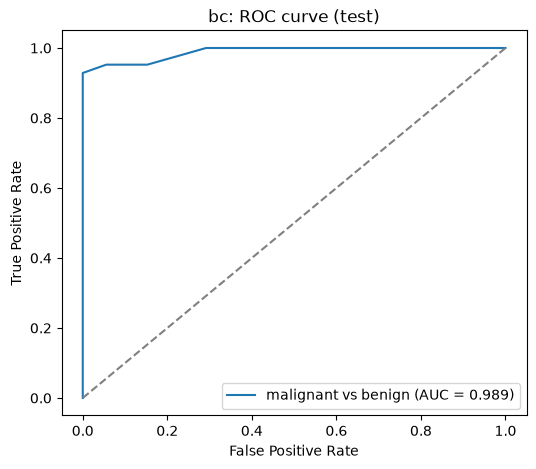

In [42]:
# malignant'ı 1 yapan değerlendirme hedefi ve malignant olasılığı
poz = list(final_model.classes_).index(0)
olasilik_m = final_model.predict_proba(X_test_final)[:, poz]
fpr, tpr, _ = roc_curve((y_test == 0).astype(int), olasilik_m)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"malignant vs benign (AUC = {test_metrikleri['test_roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"{DATASET}: ROC curve (test)")
plt.legend()
plt.savefig("figures/bc_roc_curve.png", bbox_inches="tight")
plt.show()

ROC eğrisi sol üst köşeye çok yakın, AUC 0.989. Model malignant olasılığı verdiği için hangi eşikten sonra "malignant" diyeceğimizi değiştirebiliriz. Eşiği düşürürsek daha çok hastaya malignant der, FN azalır ama FP artar. Eşiği yükseltirsek tersi olur. Burada eşiği değiştirmedim, test setiyle de hiçbir ayar yapmadım, grafik sadece göstermek için.

## 9.4 Error interpretation

In [43]:
# test setinde yanlış tahmin edilen hastalar
hatalar = pd.DataFrame({"actual": y_test, "predicted": test_tahmin}, index=X_test.index)
hatalar = hatalar[hatalar["actual"] != hatalar["predicted"]]
print("Hatalı tahmin sayısı:", len(hatalar))
hatalar.join(X_test[["mean radius", "mean area", "worst concave points"]])

Hatalı tahmin sayısı: 3


,actual,predicted,mean radius,mean area,worst concave points
41,0,1,10.95,371.1,0.1424
73,0,1,13.80,584.1,0.1383
205,0,1,15.12,716.6,0.1252


Testte 3 hata var ve üçü de aynı türden: malignant olan hastaya benign denmiş (FN). Mesela 41 numaralı hastanın mean area'sı 371, mean radius'u 10.95. Bu değerler küçük, benign hastalara benziyor, o yüzden KNN en yakın komşularını benign hastalardan bulmuş. Bu hata türü tıbbi olarak daha tehlikeli, çünkü kanserli bir hasta gözden kaçmış oluyor.

Sınırlamalar: validation seti küçük (57 hasta), 3 seed'deki train/validation grupları birbiriyle örtüşüyor yani bağımsız değiller, ve testi sadece önceden seçtiğim seed 42 modeliyle yaptım. Bu yüzden 0.971'lik test F1'i kesin bir genelleme olarak düşünmemek lazım.

# 10. K-Means Clustering
## 10.1 Fit the clustering model

In [44]:
N_CLUSTERS = len(np.unique(Y))   # Breast Cancer: 2, Wine'da 3 olacak

# silhouette en az 2 farklı küme ister ve küme sayısı örnek sayısından az olmalı, değilse NaN
def guvenli_silhouette(Xs, kumeler):
    k = len(np.unique(kumeler))
    if 2 <= k < len(Xs):
        return silhouette_score(Xs, kumeler)
    return np.nan

km_runs = []
kmeans_s42 = {}   # seed 42 modelleri test için
for seed in SEEDS:
    for rep in ["unscaled", "scaled"]:
        if rep == "unscaled":
            Xtr, Xv = splits[seed]["X_train"], splits[seed]["X_val"]
        else:
            Xtr, Xv = splits[seed]["X_train_scaled"], splits[seed]["X_val_scaled"]
        yv = splits[seed]["y_val"]

        km = KMeans(n_clusters=N_CLUSTERS, random_state=seed, n_init=10)
        km.fit(Xtr)                      # y verilmiyor, sadece özellikler
        val_kume = km.predict(Xv)
        km_runs.append({"run_id": f"{DATASET}_kmeans_{rep}_s{seed}", "dataset": DATASET,
                        "seed": seed, "representation": rep,
                        "train_inertia": km.inertia_,
                        "val_ari": adjusted_rand_score(yv, val_kume),
                        "val_silhouette": guvenli_silhouette(Xv, val_kume)})
        if seed == 42:
            kmeans_s42[rep] = km

kmeans_runs = pd.DataFrame(km_runs)
kmeans_runs

,run_id,dataset,seed,representation,train_inertia,val_ari,val_silhouette
0,bc_kmeans_unscaled_s42,bc,42,unscaled,5.156538e+07,0.399462,0.638725
1,bc_kmeans_scaled_s42,bc,42,scaled,7.918810e+03,0.451557,0.285448
2,bc_kmeans_unscaled_s52,bc,52,unscaled,4.919078e+07,0.612245,0.697473
3,bc_kmeans_scaled_s52,bc,52,scaled,8.003001e+03,0.558609,0.375031
4,bc_kmeans_unscaled_s62,bc,62,unscaled,5.305649e+07,0.501339,0.695777
5,bc_kmeans_scaled_s62,bc,62,scaled,7.922515e+03,0.733598,0.275781


In [45]:
# inertia'yı scaled ve unscaled arasında karşılaştırmıyoruz, birimleri farklı
kmeans_summary = kmeans_runs.groupby("representation").agg(
    train_inertia_mean=("train_inertia", "mean"), train_inertia_std=("train_inertia", "std"),
    val_ari_mean=("val_ari", "mean"), val_ari_std=("val_ari", "std"),
    val_silhouette_mean=("val_silhouette", "mean"), val_silhouette_std=("val_silhouette", "std"),
    valid_silhouette_count=("val_silhouette", "count")).reset_index()
kmeans_summary.insert(0, "dataset", DATASET)
kmeans_summary

,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_silhouette_count
0,bc,scaled,7.948109e+03,4.757427e+01,0.581255,0.142378,0.312086,0.054725,3
1,bc,unscaled,5.127088e+07,1.949607e+06,0.504349,0.106423,0.677325,0.033440,3


K-Means'i her seed için hem unscaled hem scaled train verisinde, y'yi hiç vermeden çalıştırdım (6 fit). Validation'da ortalama ARI scaled'da 0.581, unscaled'da 0.504 çıktı, yani scaling sonrası kümeler gerçek sınıflara daha çok benziyor. Silhouette ise unscaled'da daha yüksek (0.677 vs 0.312) ama bu ikisini direkt karşılaştırmak doğru değil, çünkü silhouette kullanılan uzaklığa göre hesaplanıyor ve unscaled'da uzaklığı neredeyse sadece area gibi büyük sütunlar belirliyor. Inertia'yı da aynı sebeple scaled ve unscaled arasında karşılaştırmadım. Seed'ler arasında ARI std'si 0.10-0.14, yani bölmeye göre biraz değişiyor.

## 10.2 Final cluster evaluation on the fixed test sets

In [46]:
km_test = []
test_kumeler = {}
for rep in ["unscaled", "scaled"]:
    Xt = X_test if rep == "unscaled" else X_test_scaled
    kume = kmeans_s42[rep].predict(Xt)
    test_kumeler[rep] = kume
    sayimlar = pd.Series(kume).value_counts().sort_index()
    km_test.append({"dataset": DATASET, "representation": rep, "seed": 42,
                    "test_cluster_counts": str(sayimlar.to_dict()),
                    "test_ari": adjusted_rand_score(y_test, kume),
                    "test_silhouette": guvenli_silhouette(Xt, kume)})
kmeans_test = pd.DataFrame(km_test)
kmeans_test

,dataset,representation,seed,test_cluster_counts,test_ari,test_silhouette
0,bc,unscaled,42,"{0: 86, 1: 28}",0.558488,0.711999
1,bc,scaled,42,"{0: 74, 1: 40}",0.735381,0.325062


In [47]:
# K-Means: Gerçek sınıflar ile tahmin edilen kümeleri karşılaştır

for rep in ["unscaled", "scaled"]:

    print("\n" + "=" * 50)
    print("Representation:", rep)
    print("=" * 50)

    tablo = pd.crosstab(
        pd.Series(np.asarray(y_test), name="Gerçek sınıf"),
        pd.Series(test_kumeler[rep], name="K-Means kümesi"),
        margins=True,
        margins_name="Toplam"
    )

    tablo.index = [
        "Malignant (0)" if x == 0 else
        "Benign (1)" if x == 1 else x
        for x in tablo.index
    ]

    display(tablo)

    print(
        "Test ARI:",
        round(
            adjusted_rand_score(y_test, test_kumeler[rep]),
            4
        )
    )


Representation: unscaled


K-Means kümesi,0,1,Toplam
Malignant (0),14,28,42
Benign (1),72,0,72
Toplam,86,28,114


Test ARI: 0.5585

Representation: scaled


K-Means kümesi,0,1,Toplam
Malignant (0),5,37,42
Benign (1),69,3,72
Toplam,74,40,114


Test ARI: 0.7354


### K-Means Test Sonuçlarının Değerlendirilmesi

K-Means modelleri, seed 42 ile oluşturulan eğitim verisi üzerinde eğitilmiş ve sabit test kümesinde yeniden eğitilmeden değerlendirilmiştir.

Test kümesinde 42 malignant (0) ve 72 benign (1) olmak üzere toplam 114 örnek bulunmaktadır.

Ölçeklendirilmemiş verilerle eğitilen K-Means modelinin test ARI değeri yaklaşık **0.558**, ölçeklendirilmiş verilerle eğitilen modelin test ARI değeri ise yaklaşık **0.735** olmuştur.

Bu sonuçlar, StandardScaler uygulandığında K-Means kümelerinin gerçek sınıf etiketleriyle daha yüksek düzeyde örtüştüğünü göstermektedir.

Contingency tabloları, gerçek malignant ve benign sınıflarının K-Means tarafından oluşturulan iki kümeye nasıl dağıldığını göstermektedir. K-Means denetimsiz bir algoritma olduğundan küme numaraları doğrudan sınıf etiketlerini temsil etmez. Bu nedenle değerlendirmede küme numaralarını sınıf numaralarıyla eşitlemek yerine Adjusted Rand Index (ARI) kullanılmıştır.

Sonuç olarak bu veri setinde ölçeklendirme, K-Means'in gerçek sınıflara benzer kümeler oluşturmasına katkı sağlamıştır.

## 10.3 Visualise and interpret the clusters

Seçilen özellikler: worst concave points ve mean concave points


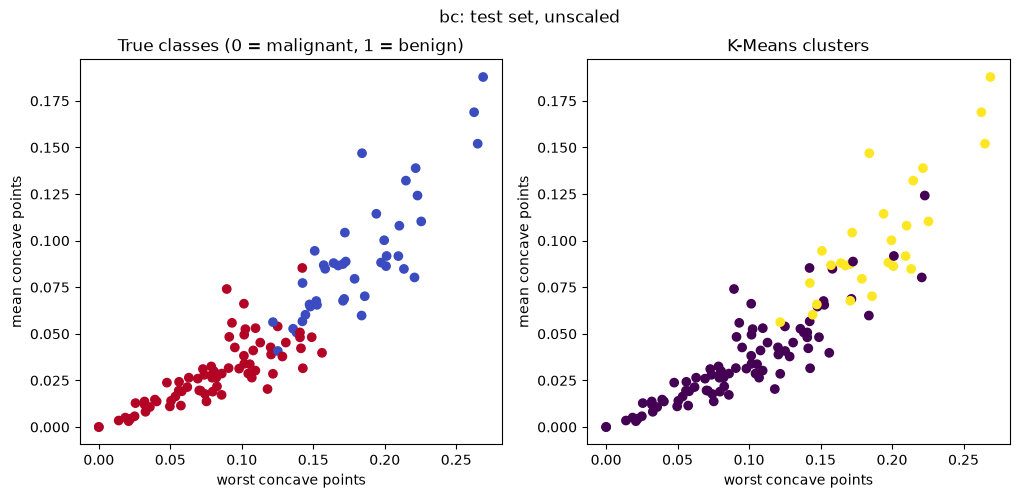

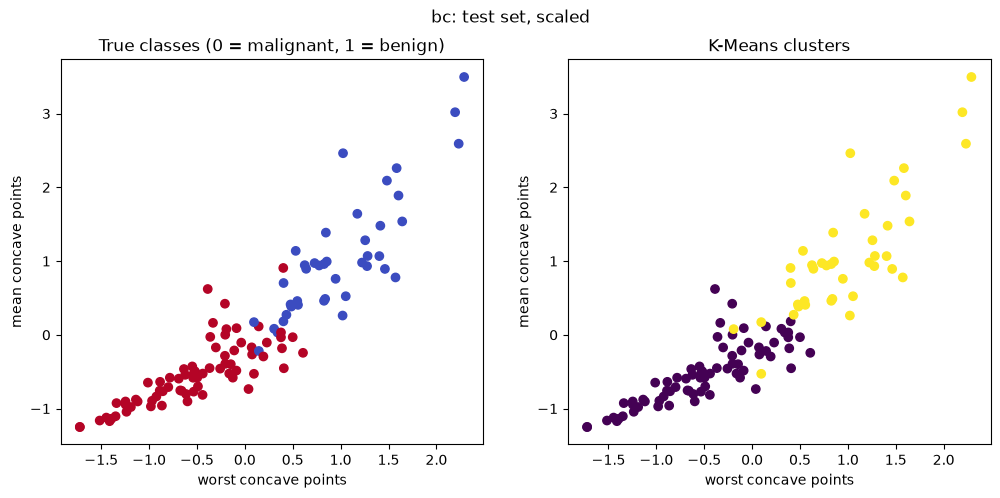

In [48]:
# seed 42 train verisinde y ile en güçlü korelasyonu olan 2 özelliği seç
tr42 = splits[42]["X_train"]
y_kor = tr42.corrwith(pd.Series(splits[42]["y_train"], index=tr42.index)).abs()
f1, f2 = y_kor.sort_values(ascending=False).index[:2]
print("Seçilen özellikler:", f1, "ve", f2)

for rep in ["unscaled", "scaled"]:
    Xt = X_test if rep == "unscaled" else X_test_scaled
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].scatter(Xt[f1], Xt[f2], c=y_test, cmap="coolwarm")
    ax[0].set_title("True classes (0 = malignant, 1 = benign)")
    ax[1].scatter(Xt[f1], Xt[f2], c=test_kumeler[rep], cmap="viridis")
    ax[1].set_title("K-Means clusters")
    for a in ax:
        a.set_xlabel(f1)
        a.set_ylabel(f2)
    fig.suptitle(f"{DATASET}: test set, {rep}")
    plt.savefig(f"figures/{DATASET}_kmeans_{rep}.png", bbox_inches="tight")
    plt.show()

Grafikler için seed 42 train verisinde sınıfla en güçlü ilişkisi olan iki özelliği seçtim: worst concave points ve mean concave points. Model aslında 30 özelliğin hepsini kullandı, bu grafik sadece iki tanesini gösteriyor. Scaled grafikte kümeler gerçek sınıflara oldukça benziyor, sadece ortadaki geçiş bölgesinde karışma var. Unscaled'da sarı küme sadece en uç malignant hastaları almış, birçok malignant hasta mor kümede kalmış, çünkü scale etmeyince K-Means'i area gibi büyük sütunlar yönetiyor.

K-Means ile classifier'ların farkı: Decision Tree, KNN ve Naive Bayes eğitilirken y_train'i yani doğru cevapları gördü. K-Means ise sadece özellikleri gördü, hiç etiket görmedi. Etiketleri sadece sonradan değerlendirme yaparken (ARI, contingency tablosu) kullandım.


In [49]:
# sonuç tablolarını CSV olarak kaydet (Wine notebook'u da kendi tablolarını ekleyecek)
runs_df.to_csv("bc_classifier_runs.csv", index=False)
summary.to_csv("bc_classifier_summary.csv", index=False)
classifier_test.to_csv("bc_classifier_test.csv", index=False)
kmeans_runs.to_csv("bc_kmeans_runs.csv", index=False)
kmeans_summary.to_csv("bc_kmeans_summary.csv", index=False)
kmeans_test.to_csv("bc_kmeans_test.csv", index=False)

In [50]:
from pathlib import Path
import pandas as pd

# Breast Cancer CSV dosyalarını kontrol et
beklenen_dosyalar = {
    "bc_classifier_runs.csv": 66,
    "bc_classifier_summary.csv": 22,
    "bc_classifier_test.csv": 1,
    "bc_kmeans_runs.csv": 6,
    "bc_kmeans_summary.csv": 2,
    "bc_kmeans_test.csv": 2
}

for dosya, beklenen_satir in beklenen_dosyalar.items():
    yol = Path(dosya)

    assert yol.exists(), f"Dosya bulunamadı: {dosya}"

    tablo = pd.read_csv(yol)
    gercek_satir = len(tablo)

    print(f"{dosya}: {gercek_satir} satır")

    assert gercek_satir == beklenen_satir, (
        f"{dosya}: {beklenen_satir} satır bekleniyordu, "
        f"{gercek_satir} bulundu."
    )

print("\nTüm Breast Cancer CSV kontrolleri başarılı!")

bc_classifier_runs.csv: 66 satır
bc_classifier_summary.csv: 22 satır
bc_classifier_test.csv: 1 satır
bc_kmeans_runs.csv: 6 satır
bc_kmeans_summary.csv: 2 satır
bc_kmeans_test.csv: 2 satır

Tüm Breast Cancer CSV kontrolleri başarılı!
